In [105]:
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import StratiﬁedKFold, GridSearchCV


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

In [106]:
phishing = fetch_ucirepo(id=327)

X = phishing.data.features.copy()
y = phishing.data.targets.copy()

y = y.squeeze()

In [107]:
if set(y.unique()) == {-1, 1}:
    y = y.map({-1: 0, 1: 1})


In [108]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.10,
    random_state=42,
    stratify=y
)

print("\n--- DATA SPLIT ---")
print("Training:", len(X_train))
print("Test:", len(X_test))

print("\nPercentages:")
print("Training:", round(len(X_train) / len(X) * 100, 2), "%")
print("Test:", round(len(X_test) / len(X) * 100, 2), "%")


--- DATA SPLIT ---
Training: 9949
Test: 1106

Percentages:
Training: 90.0 %
Test: 10.0 %


In [109]:
model = XGBClassifier(
    n_estimators=1000,
    min_child_weight=2,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=1,

    objective="binary:logistic",
    eval_metric="logloss",

    random_state=42,
    n_jobs=-1
)

In [110]:
param_grid = {
    "learning_rate": [0.05, 0.1, 0.2],
    "max_depth": [2, 4, 6]
}

In [111]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [112]:
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

In [113]:
grid_search.fit(
    X_train,
    y_train
)

Fitting 3 folds for each of 9 candidates, totalling 27 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.05, 0.1, ...], 'max_depth': [2, 4, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_i

In [114]:

print("\nBEST PARAMETERS:")
print(grid_search.best_params_)

print("\nBEST CROSS-VALIDATION F1:")
print(f"{grid_search.best_score_:.3f}")

best_model = grid_search.best_estimator_


BEST PARAMETERS:
{'learning_rate': 0.2, 'max_depth': 6}

BEST CROSS-VALIDATION F1:
0.972


In [115]:
test_pred = best_model.predict(X_test)
test_prob = best_model.predict_proba(X_test)[:, 1]

print("FINAL TEST RESULTS")
print(f"Accuracy:  {accuracy_score(y_test, test_pred):.3f}")
print(f"Precision: {precision_score(y_test, test_pred):.3f}")
print(f"Recall:    {recall_score(y_test, test_pred):.3f}")
print(f"F1:        {f1_score(y_test, test_pred):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, test_prob):.3f}")

print("\nClassification report:")
print(classification_report(y_test, test_pred, digits=3))

FINAL TEST RESULTS
Accuracy:  0.972
Precision: 0.970
Recall:    0.981
F1:        0.975
ROC-AUC:   0.997

Classification report:
              precision    recall  f1-score   support

           0      0.975     0.961     0.968       490
           1      0.970     0.981     0.975       616

    accuracy                          0.972      1106
   macro avg      0.972     0.971     0.972      1106
weighted avg      0.972     0.972     0.972      1106



In [116]:
train_pred = best_model.predict(X_train)
train_prob = best_model.predict_proba(X_train)[:, 1]

print("--- TRAINING RESULTS ---")
print(f"Accuracy:  {accuracy_score(y_train, train_pred):.3f}")
print(f"Precision: {precision_score(y_train, train_pred):.3f}")
print(f"Recall:    {recall_score(y_train, train_pred):.3f}")
print(f"F1:        {f1_score(y_train, train_pred):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_train, train_prob):.3f}")

--- TRAINING RESULTS ---
Accuracy:  0.990
Precision: 0.989
Recall:    0.994
F1:        0.991
ROC-AUC:   1.000


In [117]:
best_index = grid_search.best_index_

train_f1 = grid_search.cv_results_["mean_train_score"][best_index]
cv_f1 = grid_search.cv_results_["mean_test_score"][best_index]

print("OVERFITTING CHECK")
print(f"Training F1:     {train_f1:.3f}")
print(f"Cross-val F1:    {cv_f1:.3f}")
print(f"Difference:      {train_f1 - cv_f1:.3f}")

OVERFITTING CHECK
Training F1:     0.992
Cross-val F1:    0.972
Difference:      0.020


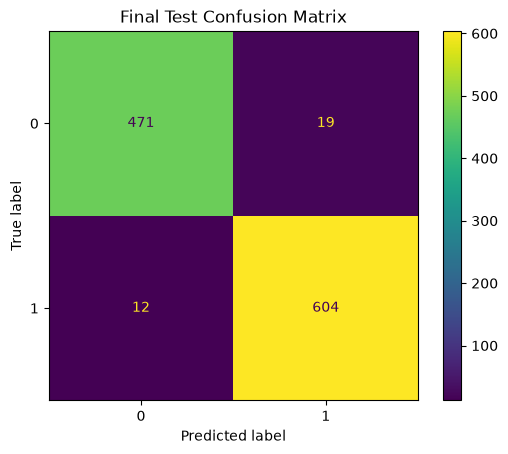

In [118]:
test_pred = best_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(y_test, test_pred)
plt.title("Final Test Confusion Matrix")
plt.show()


--- FEATURE IMPORTANCE ---
prefix_suffix          0.321562
url_of_anchor          0.268840
sslfinal_state         0.102163
rightclick             0.049080
shortining_service     0.021628
favicon                0.021003
sfh                    0.015061
port                   0.014572
submitting_to_email    0.011663
on_mouseover           0.011367
abnormal_url           0.011074
google_index           0.011068
web_traffic            0.010377
iframe                 0.009971
statistical_report     0.009952
dtype: float32


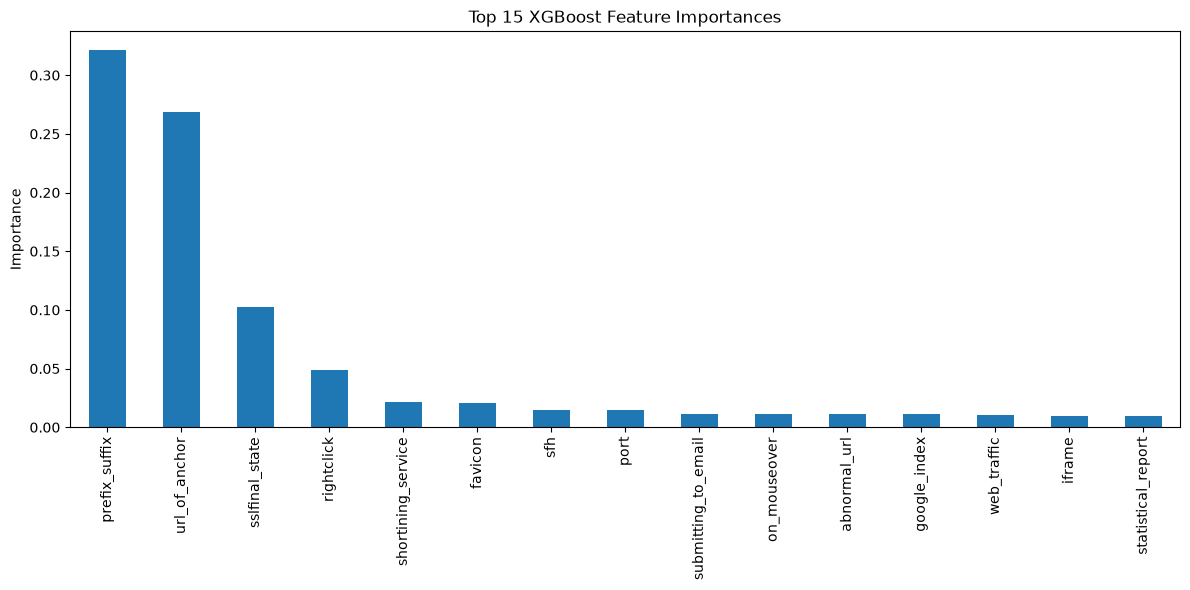

In [119]:
importance = pd.Series(

    best_model.feature_importances_,

    index=X.columns

).sort_values(
    ascending=False
)


print("\n--- FEATURE IMPORTANCE ---")

print(
    importance.head(15)
)


importance.head(15).plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Top 15 XGBoost Feature Importances"
)

plt.ylabel(
    "Importance"
)

plt.tight_layout()

plt.show()

In [120]:
'''RUN_FINAL_TEST = False

if RUN_FINAL_TEST:
    test_pred = model.predict(X_test)
    test_prob = model.predict_proba(X_test)[:, 1]

    print("\n--- FINAL TEST RESULTS ---")
    print(f"Accuracy:  {accuracy_score(y_test, test_pred):.3f}")
    print(f"Precision: {precision_score(y_test, test_pred):.3f}")
    print(f"Recall:    {recall_score(y_test, test_pred):.3f}")
    print(f"F1:        {f1_score(y_test, test_pred):.3f}")
    print(f"ROC-AUC:   {roc_auc_score(y_test, test_prob):.3f}")

    print("\nClassification report:")
    print(classification_report(y_test, test_pred, digits=2))

    ConfusionMatrixDisplay.from_predictions(y_test, test_pred)
    plt.title("Final Test Confusion Matrix")
    plt.show()
'''

'RUN_FINAL_TEST = False\n\nif RUN_FINAL_TEST:\n    test_pred = model.predict(X_test)\n    test_prob = model.predict_proba(X_test)[:, 1]\n\n    print("\n--- FINAL TEST RESULTS ---")\n    print(f"Accuracy:  {accuracy_score(y_test, test_pred):.3f}")\n    print(f"Precision: {precision_score(y_test, test_pred):.3f}")\n    print(f"Recall:    {recall_score(y_test, test_pred):.3f}")\n    print(f"F1:        {f1_score(y_test, test_pred):.3f}")\n    print(f"ROC-AUC:   {roc_auc_score(y_test, test_prob):.3f}")\n\n    print("\nClassification report:")\n    print(classification_report(y_test, test_pred, digits=2))\n\n    ConfusionMatrixDisplay.from_predictions(y_test, test_pred)\n    plt.title("Final Test Confusion Matrix")\n    plt.show()\n'